# Module 8 Lab: AI-Assisted Exploratory Analysis (Penguins)

**Name:** Roey Kadur

**GitHub Repo:** https://github.com/roee0910/cs82a-portfolio.git

**Goal:** use an AI assistant to speed up an exploratory analysis of a dataset I have never seen, **verify** its output against my own ground truth, and document the collaboration honestly.

**Plan:** (1) load the data, (2) compute ground truth myself, (3-4) prompt the AI and run its code, (5) verify, (6) one follow-up + judgment, (7) my own insight, (8) privacy reflection.

## Step 1: Load the data
Upload `penguins.csv` to Colab (the cell is skipped if the file is already there), then read it with pandas.

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Upload only if the file is not already in the working folder
if not os.path.exists("penguins.csv"):
    try:
        from google.colab import files
        files.upload()          # choose penguins.csv in the pop-up
    except ImportError:
        raise FileNotFoundError("penguins.csv not found in this folder")

df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Step 2: Ground truth by hand (no AI)
Three facts I compute **before** asking the AI anything: the shape, the missing values per column, and the number of penguins per species. Every AI claim must agree with these.

In [2]:
print("Shape (rows, columns):", df.shape)
print("\nMissing values per column:")
print(df.isna().sum().to_string())
print("\nPenguins per species:")
print(df["species"].value_counts().to_string())

# Check the dataset structure and the facts recorded in the truth table below.
assert df.shape == (344, 8), f"Expected (344, 8), got {df.shape}"
assert df["species"].value_counts().to_dict() == {"Adelie": 152, "Gentoo": 124, "Chinstrap": 68}
expected_missing = {"bill_length_mm": 2, "bill_depth_mm": 2, "flipper_length_mm": 2, "body_mass_g": 2, "sex": 11}
actual_missing = df.isna().sum()
assert {col: int(actual_missing[col]) for col in expected_missing} == expected_missing
assert int(actual_missing.drop(labels=list(expected_missing)).sum()) == 0


Shape (rows, columns): (344, 8)

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0

Penguins per species:
species
Adelie       152
Gentoo       124
Chinstrap     68


### My truth table
| Fact | Value |
|---|---|
| Shape | 344 rows x 8 columns |
| Missing values | `bill_length_mm` 2, `bill_depth_mm` 2, `flipper_length_mm` 2, `body_mass_g` 2, `sex` 11 (other columns: 0) |
| Species counts | Adelie 152, Gentoo 124, Chinstrap 68 (sum = 344) |

Note: the 2 missing measurements are in the **same** two rows (all four measurements are empty there), while `sex` is missing in 11 rows.

## Step 3: Prompt Log
**AI assistant used:** Claude (Anthropic). The prompt below is the full text I sent, built from the Tutorial 3 template with this dataset's real columns and dtypes.

### Prompt Log

**Prompt 1 (full text):**

```
You are helping with exploratory data analysis.
My CSV (penguins.csv, 344 rows) has columns:
species (text), island (text), bill_length_mm (float), bill_depth_mm (float),
flipper_length_mm (float), body_mass_g (float), sex (text), year (int).
It already loads into a pandas DataFrame called df.
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.
```

## Step 4: The AI's code (pasted as returned, then run)
Three cells, one per task in the prompt.

In [3]:
# --- AI code, part 1: summarize missing data ---
# Count missing values in every column and keep only the columns that have any
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing)

Columns with missing values:
sex                  11
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
dtype: int64


In [4]:
# --- AI code, part 2: compare flipper length across species ---
# Remove rows that contain any missing value so the comparison is "clean"
df_clean = df.dropna()
print("Rows after dropna:", len(df_clean))

# Count, mean and standard deviation of flipper length for each species
summary = df_clean.groupby("species")["flipper_length_mm"].agg(["count", "mean", "std"]).round(2)
print(summary)

Rows after dropna: 333
           count    mean   std
species                       
Adelie       146  190.10  6.52
Chinstrap     68  195.82  7.13
Gentoo       119  217.24  6.59


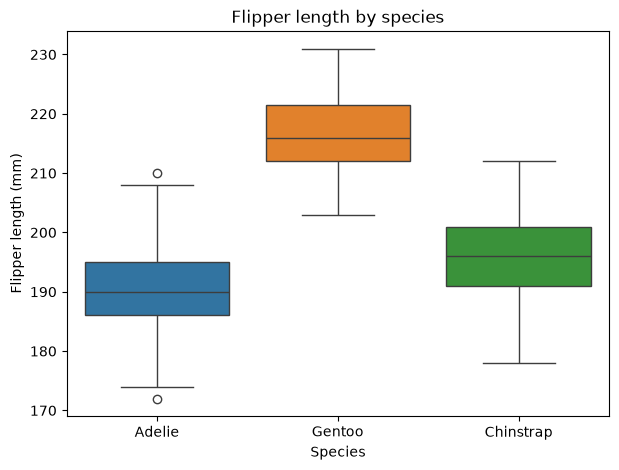

In [5]:
# --- AI code, part 3: one labeled chart ---
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x="species", y="flipper_length_mm", hue="species", legend=False)
plt.title("Flipper length by species")
plt.xlabel("Species")
plt.ylabel("Flipper length (mm)")
plt.show()

**Prompt Log, fixes:** All three AI cells ran without errors on the first try, so no fix was needed.
(The AI used my exact column names because I pasted them into the prompt.)

## Step 5: Verification checkpoint
The AI reported per-species mean flipper lengths **after `df.dropna()`**. I now compute the same thing myself with one `groupby` line on the full data, and compare.

In [6]:
# Compare the full-data mean with the AI mean after its df.dropna() step.
# mean() skips only missing flipper lengths; dropna() also removes rows missing other fields.
mine = df.groupby("species")["flipper_length_mm"].mean()
ai = df_clean.groupby("species")["flipper_length_mm"].mean()
comparison = pd.DataFrame({"mine (all known flippers)": mine, "AI (dropna)": ai})
comparison["difference (AI - mine)"] = comparison["AI (dropna)"] - comparison["mine (all known flippers)"]
print(comparison.round(3))
print("\nSpecies matching within 0.001 mm:", list(comparison.index[(comparison["difference (AI - mine)"].abs() < 0.001)]))

# Verify the dropna effect using rows with known flipper lengths.
valid_flipper = df["flipper_length_mm"].notna()
assert int((valid_flipper & df.isna().any(axis=1)).sum()) == 9
assert int((valid_flipper & ~df.isna().any(axis=1)).sum()) == 333


           mine (all known flippers)  AI (dropna)  difference (AI - mine)
species                                                                  
Adelie                       189.954      190.103                   0.149
Chinstrap                    195.824      195.824                   0.000
Gentoo                       217.187      217.235                   0.048

Species matching within 0.001 mm: ['Chinstrap']


In [7]:
# A row is discarded by dropna() when any column is missing, even if its flipper length is known.
flipper_known = df["flipper_length_mm"].notna()
dropped_by_ai = df.isna().any(axis=1)

print("Rows removed by dropna():", int(dropped_by_ai.sum()))
print("  with flipper length missing:", int((dropped_by_ai & ~flipper_known).sum()))
print("  with flipper length present:", int((dropped_by_ai & flipper_known).sum()))
print("\nKnown flipper measurements used per species:")
counts = pd.DataFrame({
    "all rows with known flipper": df.groupby("species")["flipper_length_mm"].count(),
    "after AI dropna()": df_clean.groupby("species")["flipper_length_mm"].count(),
})
print(counts)

# The dropped, otherwise usable measurements are from Adelie and Gentoo.
assert int((dropped_by_ai & flipper_known).sum()) == 9
assert int((dropped_by_ai & flipper_known & df["species"].eq("Adelie")).sum()) == 5
assert int((dropped_by_ai & flipper_known & df["species"].eq("Gentoo")).sum()) == 4
assert int((dropped_by_ai & flipper_known & df["species"].eq("Chinstrap")).sum()) == 0


Rows removed by dropna(): 11
  with flipper length missing: 2
  with flipper length present: 9

Known flipper measurements used per species:
           all rows with known flipper  after AI dropna()
species                                                  
Adelie                             151                146
Chinstrap                           68                 68
Gentoo                             123                119


**Prompt Log, verification result: MISMATCH (small, and explained).**

| Species | My mean | AI mean | Match? |
|---|---|---|---|
| Adelie | 189.95 | 190.10 | no |
| Chinstrap | 195.82 | 195.82 | yes |
| Gentoo | 217.19 | 217.24 | no |

**Why:** `df.dropna()` deletes any row with *any* missing value. 11 rows were dropped: 2 have no measurements at all, but 9 rows have a valid flipper length and are only missing `sex`. Those 9 penguins are all Adelie (5) or Gentoo (4), which is exactly why only those two species changed. Chinstrap has no missing values, so it matches.

**Which number I trust:** mine. My `groupby` uses every penguin that actually has a flipper measurement (151 Adelie, 123 Gentoo), while the AI threw away 9 valid measurements because of an unrelated column. The difference is tiny (under 0.2 mm), but the method matters.

## Step 6: One follow-up, one judgment

**Prompt 2 (full text):**

```
Thanks. Now improve the analysis: make a scatter plot of flipper_length_mm (x) vs body_mass_g (y),
colored by species, with a title and axis labels. Only drop rows missing those two columns.
```

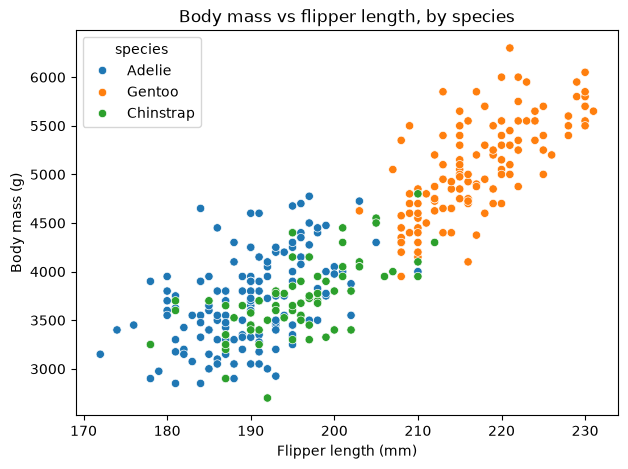

Penguins plotted: 342


In [8]:
# --- AI code, follow-up: scatter of flipper length vs body mass, colored by species ---
# Drop only rows that are missing the two columns used in this plot
plot_df = df.dropna(subset=["flipper_length_mm", "body_mass_g"])

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_df, x="flipper_length_mm", y="body_mass_g", hue="species")
plt.title("Body mass vs flipper length, by species")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.show()
print("Penguins plotted:", len(plot_df))

**Prompt Log, judgment: KEEP.** It shows that longer flippers go with heavier bodies and that Gentoo form a clearly separate, heavier cluster, which the boxplot alone could not show; it also avoids the over-aggressive `dropna()` from the first answer (342 penguins plotted instead of 333).

## Step 7: My own insight (no AI)
The AI never looked at the relationship between **bill length and bill depth**. Overall it looks negative, but inside each species it is positive.

Correlation, all penguins together: -0.235

Correlation within each species:
species
Adelie       0.391
Chinstrap    0.654
Gentoo       0.643
dtype: float64


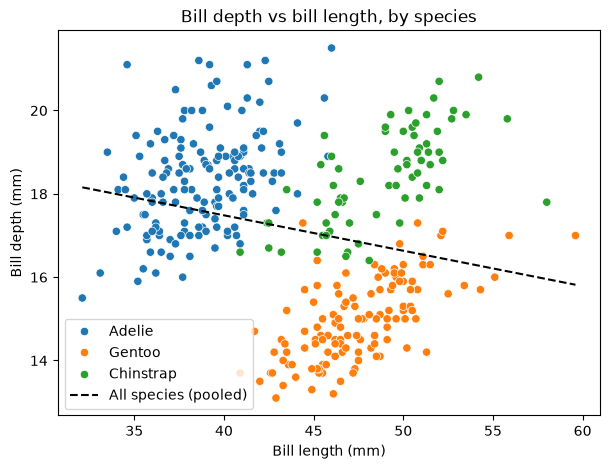

In [9]:
# Pearson correlations use only rows where both bill measurements are present.
bill_data = df.dropna(subset=["bill_length_mm", "bill_depth_mm"])
overall = bill_data["bill_length_mm"].corr(bill_data["bill_depth_mm"])
per_species = bill_data.groupby("species")[["bill_length_mm", "bill_depth_mm"]].apply(
    lambda group: group["bill_length_mm"].corr(group["bill_depth_mm"]),
)

print("Correlation, all penguins together:", round(overall, 3))
print("\nCorrelation within each species:")
print(per_species.round(3))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=bill_data, x="bill_length_mm", y="bill_depth_mm", hue="species")
# The dashed line is the single pooled linear trend; colored points show the species groups.
slope, intercept = np.polyfit(bill_data["bill_length_mm"], bill_data["bill_depth_mm"], 1)
xs = np.linspace(bill_data["bill_length_mm"].min(), bill_data["bill_length_mm"].max(), 50)
plt.plot(xs, slope * xs + intercept, color="black", linestyle="--", label="All species (pooled)")
plt.title("Bill depth vs bill length, by species")
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.legend()
plt.show()


**My insight:** When all species are combined, bill length and bill depth have a weak negative correlation (about **-0.24**). Within each species, the correlation is positive: Adelie **+0.39**, Chinstrap **+0.65**, and Gentoo **+0.64**. This reversal is an example of Simpson’s paradox: the groups differ in their typical bill shapes, so the pooled pattern can point in the opposite direction from the within-species patterns. The scatter plot makes the species clusters visible; correlation describes association and does not establish cause.

## Step 8: Privacy reflection
This dataset is public animals, so it is safe to paste into any AI tool. I must **never** paste my university grade records or any file with names, ID numbers or contact details of real people (for example a class list or a client/employer spreadsheet) into a public AI tool, because I cannot control where that data is stored or reused. Instead I would **anonymize** it (remove names and IDs), share only an **aggregate** (e.g. averages per group), or use an **approved internal tool**.